# Role 4 - Results and Analysis notebook

**How to use:** In Colab go to Runtime > Change runtime type > GPU. Then run the cells from top to bottom (press the play button on each cell, or Runtime > Run all).

**What this notebook does (your 4 tasks):**
1. Measure parameters, file size (MB) and speed (ms per image) of each model
2. Collect accuracies into a pandas table
3. Draw the charts (bar, accuracy vs size, temperature/alpha heatmap, accuracy over epochs, confusion matrix)
4. Leave space for your written conclusions

**Important:** Until the real models and results arrive (Weeks 3-4), this notebook uses FAKE placeholder accuracy numbers so you can build and test everything. Every fake cell is marked. Never put fake numbers in the report.

## Step 0 - Your GPU test (fixed)
Your first line had a typo: `mport torch` should be `import torch`. Fixed below.

In [ ]:
import torch

print('GPU available:', torch.cuda.is_available())
a = torch.tensor([1.0, 2.0, 3.0])
b = torch.tensor([4.0, 5.0, 6.0])
print('Math test result:', a + b)
print('--- Everything is working! ---')

GPU available: False
Math test result: tensor([5., 7., 9.])
--- Everything is working! ---


## Step 1 - Imports and settings
Colour rule from the guide: teacher = blue, baseline student = grey, distilled student = green. Use these in every chart.

In [ ]:
import os, time, tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch.nn as nn
from torchvision.models import resnet18

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Using device:', device)

COLORS = {'Teacher': '#1f77b4', 'Baseline': '#7f7f7f', 'KD': '#2ca02c'}
os.makedirs('charts', exist_ok=True)   # charts are saved here as PNG files
os.makedirs('results', exist_ok=True)  # tables are saved here as CSV files

Using device: cpu


## Step 2 - Placeholder models (Task 1 setup)
These are UNTRAINED stand-ins so you can test your measuring code today. The teacher is ResNet-18 (about 11 million parameters). The student is a tiny network (about 0.1 million). Later, replace them with the real ones: load `teacher.pt`, `student_baseline.pt`, `student_kd.pt` from the shared Drive (see Step 9). Ask Role 3 for the exact student definition so the sizes match.

In [ ]:
def make_teacher():
    m = resnet18(num_classes=10)
    m.conv1 = nn.Conv2d(3, 64, 3, 1, 1, bias=False)  # suits small 32x32 pictures
    m.maxpool = nn.Identity()
    return m

def make_student():
    return nn.Sequential(
        nn.Conv2d(3, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(), nn.AdaptiveAvgPool2d(1),
        nn.Flatten(), nn.Linear(128, 10))

models = {
    'Teacher': make_teacher(),
    'Baseline': make_student(),
    'KD': make_student(),   # same architecture as baseline; only the training differs
}
print('Models created:', list(models))

Models created: ['Teacher', 'Baseline', 'KD']


## Step 3 - Measure parameters, file size and speed (Task 1)
- **Parameters**: how many numbers the model has
- **Size (MB)**: how big the saved file is
- **Latency (ms)**: time to answer ONE picture (average over 100 runs, after a warm-up)

In [ ]:
def measure(model, name, runs=100):
    model = model.to(device).eval()
    params = sum(p.numel() for p in model.parameters())

    # file size: save the weights to a temporary file and check its size
    with tempfile.NamedTemporaryFile(suffix='.pt', delete=False) as f:
        path = f.name
    torch.save(model.state_dict(), path)
    size_mb = os.path.getsize(path) / 1e6
    os.remove(path)

    # speed: one 32x32 colour picture at a time
    x = torch.randn(1, 3, 32, 32, device=device)
    with torch.no_grad():
        for _ in range(20):          # warm-up (first runs are slower)
            model(x)
        if device == 'cuda':
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        for _ in range(runs):
            model(x)
        if device == 'cuda':
            torch.cuda.synchronize()
    ms = (time.perf_counter() - t0) / runs * 1000

    return {'Model': name, 'Parameters': params,
            'Size (MB)': round(size_mb, 2), 'Latency (ms)': round(ms, 3)}

measure_df = pd.DataFrame([measure(m, n) for n, m in models.items()])
measure_df['Params (millions)'] = (measure_df['Parameters'] / 1e6).round(3)
measure_df.to_csv('results/measurements.csv', index=False)
measure_df

,Model,Parameters,Size (MB),Latency (ms),Params (millions)
0,Teacher,11173962,44.77,39.758,11.174
1,Baseline,94986,0.39,2.275,0.095
2,KD,94986,0.39,2.560,0.095


## Step 4 - Experiment Log as a pandas table (Task 2)
The real data comes from the team's Google Sheet **Experiment Log**. The columns there are: Date, Who, Model, Epochs, Temp, Alpha, Seed, Accuracy %, File name, Notes.

**FAKE DATA BELOW** (for testing charts only). Set `USE_FAKE = False` in Step 9 when real results exist.

In [ ]:
rng = np.random.default_rng(0)
rows = []
# main runs: 3 seeds each
for seed in [0, 1, 2]:
    rows.append({'Model': 'Teacher',  'Temp': np.nan, 'Alpha': np.nan, 'Seed': seed, 'Accuracy': 93 + rng.normal(0, 0.3)})
    rows.append({'Model': 'Baseline', 'Temp': np.nan, 'Alpha': np.nan, 'Seed': seed, 'Accuracy': 85 + rng.normal(0, 0.4)})
    rows.append({'Model': 'KD',       'Temp': 4,      'Alpha': 0.7,    'Seed': seed, 'Accuracy': 88 + rng.normal(0, 0.4)})
# sweep: temperature x alpha (seed 0)
for T in [1, 2, 4, 8]:
    for A in [0.3, 0.5, 0.7, 0.9]:
        rows.append({'Model': 'KD-sweep', 'Temp': T, 'Alpha': A, 'Seed': 0,
                     'Accuracy': 86 + 0.4 * np.log2(T) + 1.5 * A + rng.normal(0, 0.2)})
log = pd.DataFrame(rows)
log['Accuracy'] = log['Accuracy'].round(2)
log.head(12)

,Model,Temp,Alpha,Seed,Accuracy
0,Teacher,NaN,NaN,0,93.04
1,Baseline,NaN,NaN,0,84.95
2,KD,4.0,0.7,0,88.26
3,Teacher,NaN,NaN,1,93.03
4,Baseline,NaN,NaN,1,84.79
5,KD,4.0,0.7,1,88.14
6,Teacher,NaN,NaN,2,93.39
7,Baseline,NaN,NaN,2,85.38
8,KD,4.0,0.7,2,87.72
9,KD-sweep,1.0,0.3,0,86.20


### Main results table: average and spread over 3 seeds

In [ ]:
main = log[log['Model'].isin(['Teacher', 'Baseline', 'KD'])]
summary = (main.groupby('Model')['Accuracy'].agg(['mean', 'std']).round(2)
           .reindex(['Teacher', 'Baseline', 'KD']).reset_index())
summary.columns = ['Model', 'Accuracy mean (%)', 'Accuracy std']

final_table = summary.merge(measure_df[['Model', 'Params (millions)', 'Size (MB)', 'Latency (ms)']], on='Model')
final_table.to_csv('results/final_table.csv', index=False)
final_table

,Model,Accuracy mean (%),Accuracy std,Params (millions),Size (MB),Latency (ms)
0,Teacher,93.15,0.21,11.174,44.77,39.758
1,Baseline,85.04,0.31,0.095,0.39,2.275
2,KD,88.04,0.28,0.095,0.39,2.560


## Step 5 - Chart 1: accuracy of each model (Task 3)
Goal from the guide: someone who has never seen the project should understand the result from this first chart.

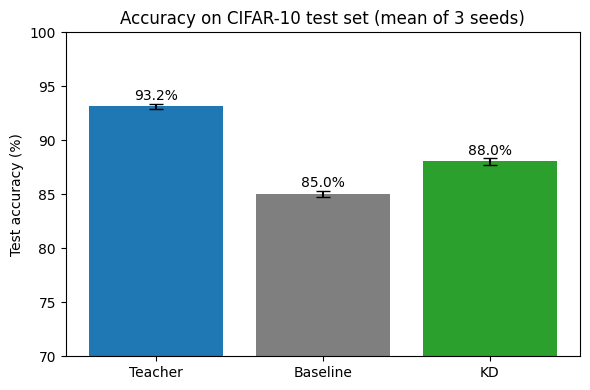

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))
names = list(summary['Model'])
bars = ax.bar(names, summary['Accuracy mean (%)'], yerr=summary['Accuracy std'],
              color=[COLORS[n] for n in names], capsize=5)
for b, v in zip(bars, summary['Accuracy mean (%)']):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.6, f'{v:.1f}%', ha='center')
ax.set_ylabel('Test accuracy (%)')
ax.set_title('Accuracy on CIFAR-10 test set (mean of 3 seeds)')
ax.set_ylim(70, 100)
plt.tight_layout()
plt.savefig('charts/1_accuracy_bar.png', dpi=200)
plt.show()

## Step 6 - Chart 2: accuracy vs size

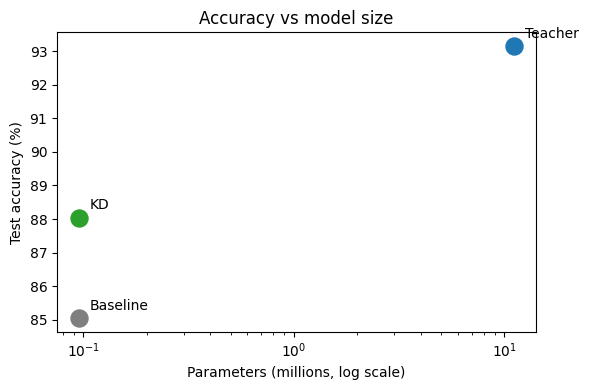

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))
for _, r in final_table.iterrows():
    ax.scatter(r['Params (millions)'], r['Accuracy mean (%)'], s=150, color=COLORS[r['Model']], label=r['Model'])
    ax.annotate(r['Model'], (r['Params (millions)'], r['Accuracy mean (%)']),
                textcoords='offset points', xytext=(8, 6))
ax.set_xscale('log')
ax.set_xlabel('Parameters (millions, log scale)')
ax.set_ylabel('Test accuracy (%)')
ax.set_title('Accuracy vs model size')
plt.tight_layout()
plt.savefig('charts/2_accuracy_vs_size.png', dpi=200)
plt.show()

## Step 7 - Chart 3: effect of temperature and alpha (heatmap)
Remember the team rule: choose the best temperature/alpha using VALIDATION accuracy, and report test accuracy last. Ask Role 3 which column holds validation accuracy when real data arrives.

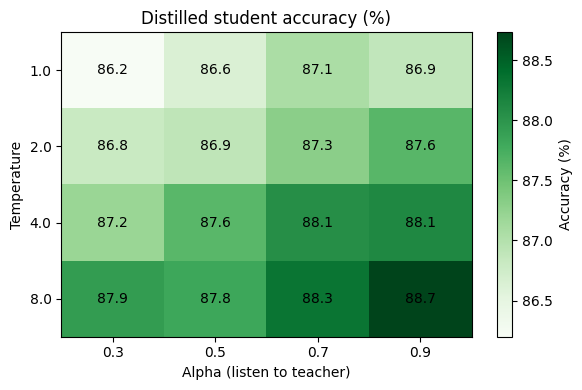

In [ ]:
sweep = log[log['Model'] == 'KD-sweep']
grid = sweep.pivot_table(index='Temp', columns='Alpha', values='Accuracy')

fig, ax = plt.subplots(figsize=(6, 4))
im = ax.imshow(grid.values, cmap='Greens', aspect='auto')
ax.set_xticks(range(len(grid.columns)), grid.columns)
ax.set_yticks(range(len(grid.index)), grid.index)
ax.set_xlabel('Alpha (listen to teacher)')
ax.set_ylabel('Temperature')
ax.set_title('Distilled student accuracy (%)')
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        ax.text(j, i, f'{grid.values[i, j]:.1f}', ha='center', va='center')
plt.colorbar(im, label='Accuracy (%)')
plt.tight_layout()
plt.savefig('charts/3_temp_alpha_heatmap.png', dpi=200)
plt.show()

## Step 8 - Chart 4: accuracy over epochs
FAKE curves for now. Real ones come from the training logs (Role 2 gives the teacher log, Role 3 the student logs).

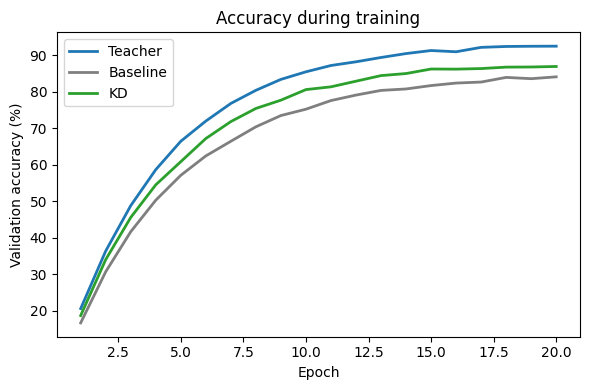

In [ ]:
epochs = np.arange(1, 21)
def fake_curve(final, speed):
    return final * (1 - np.exp(-speed * epochs)) + rng.normal(0, 0.3, len(epochs))

curves = {'Teacher': fake_curve(93, 0.25), 'Baseline': fake_curve(85, 0.22), 'KD': fake_curve(88, 0.24)}

fig, ax = plt.subplots(figsize=(6, 4))
for n, y in curves.items():
    ax.plot(epochs, y, label=n, color=COLORS[n], linewidth=2)
ax.set_xlabel('Epoch')
ax.set_ylabel('Validation accuracy (%)')
ax.set_title('Accuracy during training')
ax.legend()
plt.tight_layout()
plt.savefig('charts/4_accuracy_over_epochs.png', dpi=200)
plt.show()

### Optional (scikit-learn): confusion matrix and F1-score
Shows WHICH classes the model confuses (for example cat vs dog). FAKE predictions below; later use real predictions from each model on the test set.

Macro F1-score: 0.892


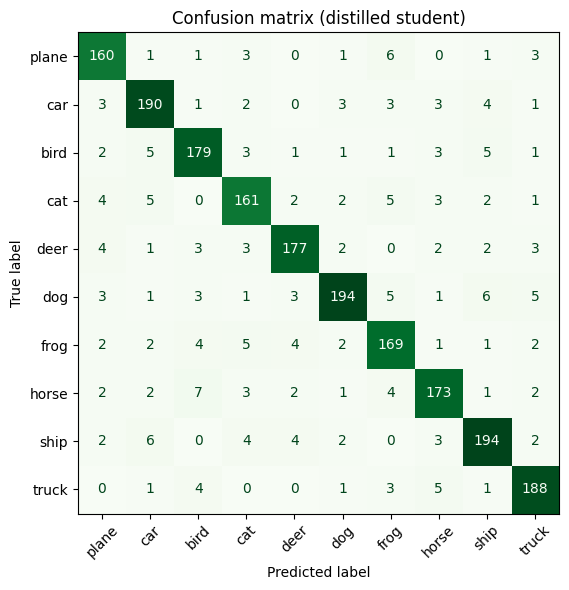

In [ ]:
from sklearn.metrics import confusion_matrix, f1_score, ConfusionMatrixDisplay

classes = ['plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
y_true = rng.integers(0, 10, 2000)                      # FAKE
y_pred = np.where(rng.random(2000) < 0.88, y_true, rng.integers(0, 10, 2000))  # FAKE

print('Macro F1-score:', round(f1_score(y_true, y_pred, average='macro'), 3))
cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(cm, display_labels=classes).plot(ax=ax, cmap='Greens', xticks_rotation=45, colorbar=False)
ax.set_title('Confusion matrix (distilled student)')
plt.tight_layout()
plt.savefig('charts/5_confusion_matrix.png', dpi=200)
plt.show()

## Step 9 - Switching to REAL data (do this in Weeks 3-4)
1. In Google Sheets: File > Download > CSV for the Experiment Log. Upload it to Colab (folder icon on the left) as `experiment_log.csv`.
2. Mount Drive to load the real models:
```python
from google.colab import drive
drive.mount('/content/drive')
m = make_teacher(); m.load_state_dict(torch.load('/content/drive/MyDrive/<folder>/teacher.pt'))
models['Teacher'] = m
```
(Do the same for the two students. If loading fails with a key error, ask Role 2/3 how they saved the file and which model definition they used.)
3. Rename the real log's columns to `Model, Temp, Alpha, Seed, Accuracy` and re-run Steps 3-8. Make sure model names are exactly `Teacher`, `Baseline`, `KD`, and `KD-sweep` for the temperature/alpha runs.

In [ ]:
USE_FAKE = True   # change to False when real results exist

if not USE_FAKE:
    raw = pd.read_csv('experiment_log.csv')
    raw = raw.rename(columns={'Accuracy %': 'Accuracy'})
    log = raw[['Model', 'Temp', 'Alpha', 'Seed', 'Accuracy']]
    print('Loaded real log with', len(log), 'rows. Now re-run Steps 3-8.')
else:
    print('Still using FAKE data. Do not copy these charts into the report!')

Still using FAKE data. Do not copy these charts into the report!


## Step 10 - Your written findings (Task 4)
Write 2-3 sentences beside each chart. Template (fill with REAL numbers):

- **Chart 1:** The distilled student reached __% versus __% for the baseline, closing __ of the __-point gap to the teacher.
- **Chart 2:** The student has __x fewer parameters and runs __x faster, while losing only __ points of accuracy.
- **Chart 3:** Best settings were temperature __ and alpha __. Very high/low values performed worse because ...
- **Limits:** Only CIFAR-10, only 3 seeds, small differences (< std) may be noise.

If distillation did NOT beat the baseline, that is a valid finding: report it honestly.

In [ ]:
!zip -r role4_outputs.zip charts results
from google.colab import files
files.download('role4_outputs.zip')

  adding: charts/ (stored 0%)
  adding: charts/3_temp_alpha_heatmap.png (deflated 10%)
  adding: charts/1_accuracy_bar.png (deflated 20%)
  adding: charts/5_confusion_matrix.png (deflated 13%)
  adding: charts/2_accuracy_vs_size.png (deflated 19%)
  adding: charts/4_accuracy_over_epochs.png (deflated 9%)
  adding: results/ (stored 0%)
  adding: results/measurements.csv (deflated 18%)
  adding: results/final_table.csv (deflated 21%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import os, torch

folder = '/content/drive/MyDrive/checkpoints'
print(os.listdir(folder))

for f in ['teacher_model.pth', 'student_baseline.pt', 'student_kd.pt']:
    obj = torch.load(os.path.join(folder, f), map_location='cpu')
    print('\n', f, type(obj))
    if isinstance(obj, dict):
        print('number of keys:', len(obj), '| first keys:', list(obj.keys())[:5])
        print('parameters:', sum(v.numel() for v in obj.values() if hasattr(v, 'numel')))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['student_baseline.pt', 'teacher_model.pth', 'benchmark_summary.csv', 'kd_comparison_plot.png', 'student_kd.pt']

 teacher_model.pth <class 'collections.OrderedDict'>
number of keys: 122 | first keys: ['conv1.weight', 'bn1.weight', 'bn1.bias', 'bn1.running_mean', 'bn1.running_var']
parameters: 11183582

 student_baseline.pt <class 'collections.OrderedDict'>
number of keys: 22 | first keys: ['features.0.weight', 'features.1.weight', 'features.1.bias', 'features.1.running_mean', 'features.1.running_var']
parameters: 189293

 student_kd.pt <class 'collections.OrderedDict'>
number of keys: 22 | first keys: ['features.0.weight', 'features.1.weight', 'features.1.bias', 'features.1.running_mean', 'features.1.running_var']
parameters: 189293


In [ ]:
import os
print(os.listdir('/content/drive/MyDrive'))

['Colab Notebooks', 'download_copy.pdf', 'Admitcard', 'Classroom', 'ayshctry.jv', 'DSW_1 (1).ipynb', 'DSW', 'ayshctry.mcsd', 'py 1.ipynb', '8b020ac0-8077-44f1-aff9-08504d0c9ed5_copy.pdf', 'checkpoints']


In [ ]:
import torch
sd = torch.load('/content/drive/MyDrive/checkpoints/student_baseline.pt', map_location='cpu')
for k, v in sd.items():
    print(k, tuple(v.shape))

features.0.weight (32, 3, 3, 3)
features.1.weight (32,)
features.1.bias (32,)
features.1.running_mean (32,)
features.1.running_var (32,)
features.1.num_batches_tracked ()
features.4.weight (64, 32, 3, 3)
features.5.weight (64,)
features.5.bias (64,)
features.5.running_mean (64,)
features.5.running_var (64,)
features.5.num_batches_tracked ()
features.8.weight (64, 64, 3, 3)
features.9.weight (64,)
features.9.bias (64,)
features.9.running_mean (64,)
features.9.running_var (64,)
features.9.num_batches_tracked ()
classifier.1.weight (128, 1024)
classifier.1.bias (128,)
classifier.4.weight (10, 128)
classifier.4.bias (10,)


,Model,Accuracy mean (%),Accuracy std,Parameters,Params (millions),Size (MB),Latency (ms),Smaller than teacher (x)
0,Teacher,90.38,0.0,11173962,11.174,44.77,80.868,1.0
1,Baseline,81.52,0.0,188970,0.189,0.77,4.293,59.1
2,KD,80.88,0.0,188970,0.189,0.77,3.307,59.1


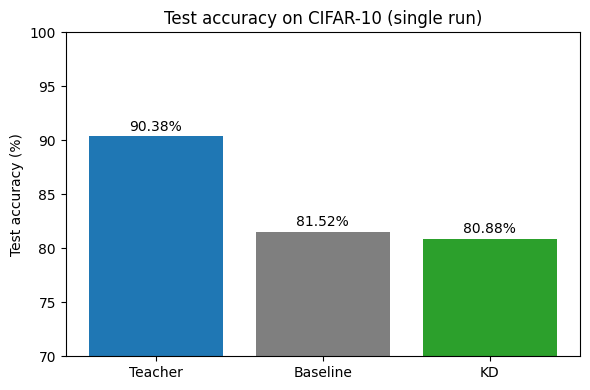

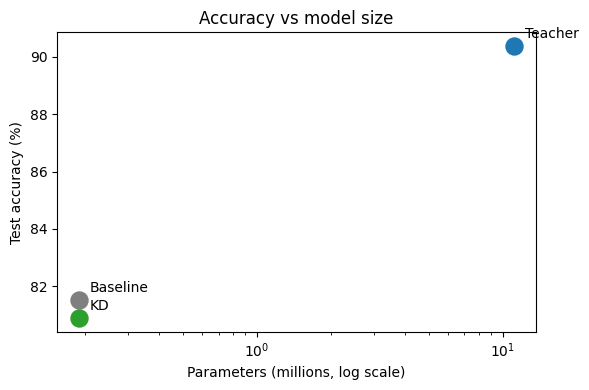

In [ ]:
import torch.nn as nn

class Student(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1, bias=False), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1, bias=False), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 64, 3, padding=1, bias=False), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2))
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(1024, 128), nn.ReLU(), nn.Dropout(0.5), nn.Linear(128, 10))
    def forward(self, x):
        return self.classifier(self.features(x))

# 1. Load the REAL models from the team's checkpoints folder
folder = '/content/drive/MyDrive/checkpoints'
teacher = make_teacher()
teacher.load_state_dict(torch.load(f'{folder}/teacher_model.pth', map_location='cpu'))
base = Student()
base.load_state_dict(torch.load(f'{folder}/student_baseline.pt', map_location='cpu'))
kd = Student()
kd.load_state_dict(torch.load(f'{folder}/student_kd.pt', map_location='cpu'))
models = {'Teacher': teacher, 'Baseline': base, 'KD': kd}

# 2. Measure parameters, size and speed (real models)
measure_df = pd.DataFrame([measure(m, n) for n, m in models.items()])
measure_df['Params (millions)'] = (measure_df['Parameters'] / 1e6).round(3)

# 3. Accuracies from the team's benchmark_summary.csv (single run each)
team_acc = {'Teacher': 90.38, 'Baseline': 81.52, 'KD': 80.88}
summary = pd.DataFrame({'Model': list(team_acc), 'Accuracy mean (%)': list(team_acc.values()),
                        'Accuracy std': [0.0, 0.0, 0.0]})
final_table = summary.merge(
    measure_df[['Model', 'Parameters', 'Params (millions)', 'Size (MB)', 'Latency (ms)']], on='Model')
t_params = final_table.loc[final_table['Model'] == 'Teacher', 'Parameters'].iloc[0]
final_table['Smaller than teacher (x)'] = (t_params / final_table['Parameters']).round(1)
final_table.to_csv('results/final_table_real.csv', index=False)
display(final_table)

# 4. Real chart 1: accuracy bars
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(final_table['Model'], final_table['Accuracy mean (%)'],
              color=[COLORS[n] for n in final_table['Model']])
for b, v in zip(bars, final_table['Accuracy mean (%)']):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.5, f'{v:.2f}%', ha='center')
ax.set_ylabel('Test accuracy (%)'); ax.set_ylim(70, 100)
ax.set_title('Test accuracy on CIFAR-10 (single run)')
plt.tight_layout(); plt.savefig('charts/real_1_accuracy_bar.png', dpi=200); plt.show()

# 5. Real chart 2: accuracy vs size
fig, ax = plt.subplots(figsize=(6, 4))
for _, r in final_table.iterrows():
    ax.scatter(r['Params (millions)'], r['Accuracy mean (%)'], s=150, color=COLORS[r['Model']])
    ax.annotate(r['Model'], (r['Params (millions)'], r['Accuracy mean (%)']),
                textcoords='offset points', xytext=(8, 6))
ax.set_xscale('log'); ax.set_xlabel('Parameters (millions, log scale)'); ax.set_ylabel('Test accuracy (%)')
ax.set_title('Accuracy vs model size')
plt.tight_layout(); plt.savefig('charts/real_2_accuracy_vs_size.png', dpi=200); plt.show()

100%|██████████| 170M/170M [20:21<00:00, 140kB/s]


normalize = True -> teacher accuracy 90.38
normalize = False -> teacher accuracy 48.79
Using normalize = True


,Model,My accuracy (%),Macro F1
0,Teacher,90.38,0.904
1,Baseline,79.71,0.797
2,KD,78.48,0.786


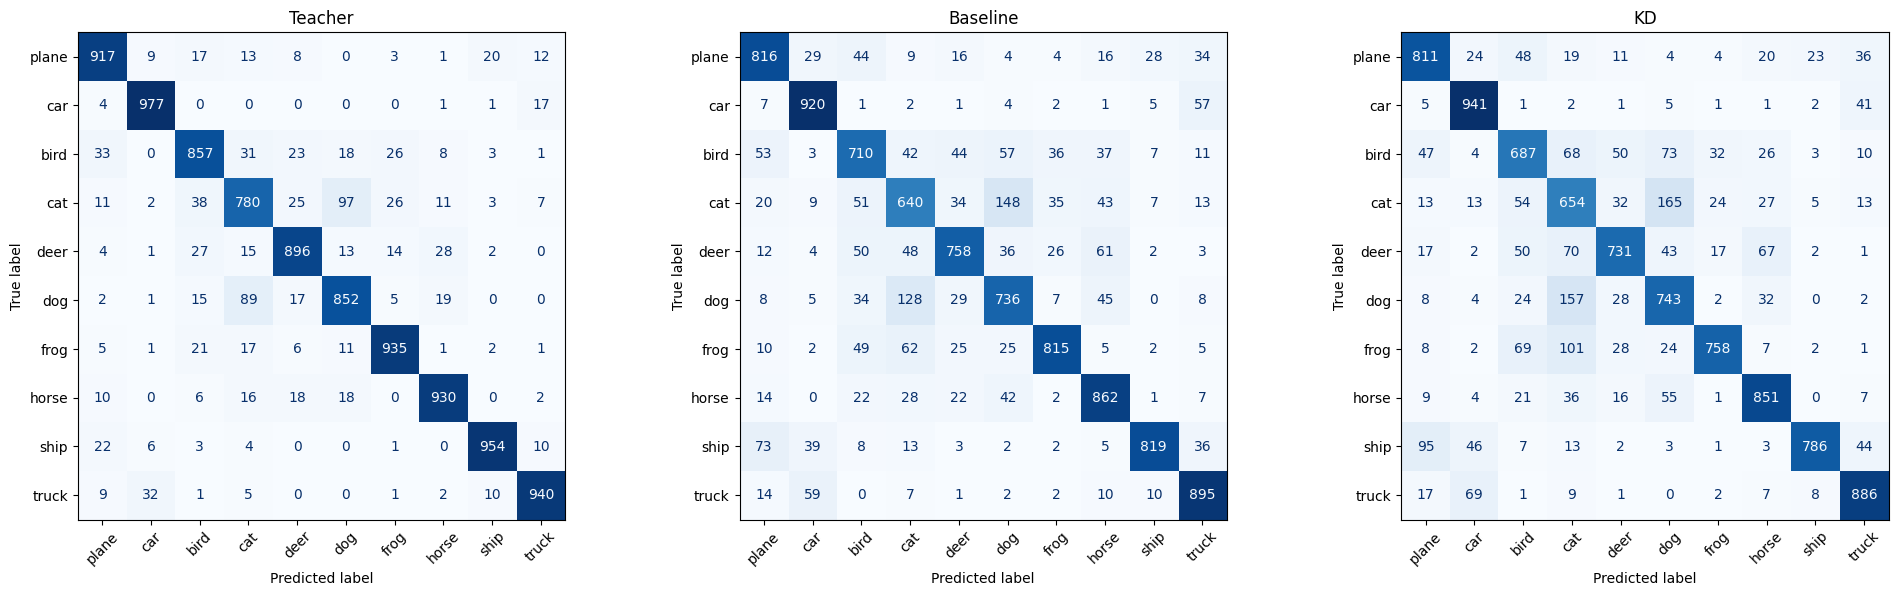

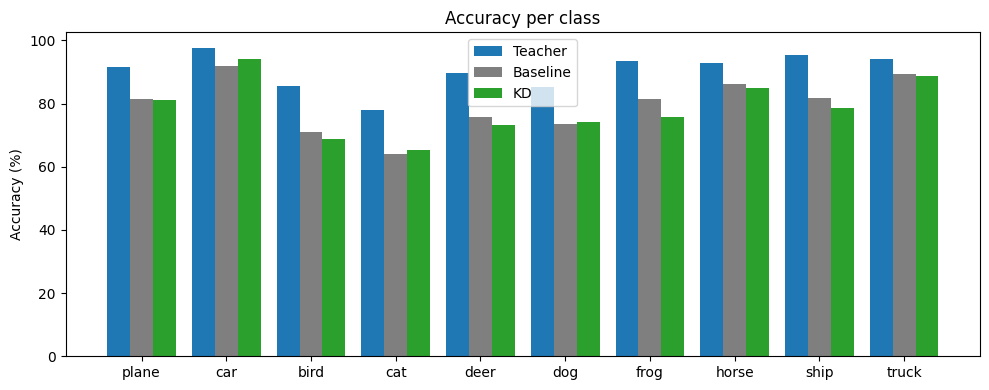

In [19]:
import torchvision, torchvision.transforms as T
from torch.utils.data import DataLoader
from sklearn.metrics import confusion_matrix, f1_score, ConfusionMatrixDisplay

classes = ['plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

def get_loader(normalize):
    tf = [T.ToTensor()]
    if normalize:
        tf.append(T.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)))
    ds = torchvision.datasets.CIFAR10('./data', train=False, download=True, transform=T.Compose(tf))
    return DataLoader(ds, batch_size=256, shuffle=False)

def predict(model, loader):
    model = model.to(device).eval()
    ys, ps = [], []
    with torch.no_grad():
        for x, y in loader:
            ps.append(model(x.to(device)).argmax(1).cpu())
            ys.append(y)
    return torch.cat(ys).numpy(), torch.cat(ps).numpy()

# Find which preprocessing the team used (the one that gives teacher ~90.38%)
accs = {}
for norm in [True, False]:
    y, p = predict(models['Teacher'], get_loader(norm))
    accs[norm] = (y == p).mean() * 100
    print('normalize =', norm, '-> teacher accuracy', round(accs[norm], 2))
best = min(accs, key=lambda n: abs(accs[n] - 90.38))
print('Using normalize =', best)
loader = get_loader(best)

# Evaluate all three models
results, cms = [], {}
for name, m in models.items():
    y, p = predict(m, loader)
    cms[name] = confusion_matrix(y, p)
    results.append({'Model': name, 'My accuracy (%)': round((y == p).mean() * 100, 2),
                    'Macro F1': round(f1_score(y, p, average='macro'), 3)})
display(pd.DataFrame(results))   # should be close to 90.38 / 81.52 / 80.88

# Chart 3: confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, name in zip(axes, models):
    ConfusionMatrixDisplay(cms[name], display_labels=classes).plot(
        ax=ax, cmap='Blues', xticks_rotation=45, colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.savefig('charts/real_3_confusion_matrices.png', dpi=200); plt.show()

# Chart 4: per-class accuracy
per_class = {n: cms[n].diagonal() / cms[n].sum(axis=1) * 100 for n in models}
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(10); w = 0.27
for i, n in enumerate(['Teacher', 'Baseline', 'KD']):
    ax.bar(x + (i - 1) * w, per_class[n], w, color=COLORS[n], label=n)
ax.set_xticks(x, classes); ax.set_ylabel('Accuracy (%)'); ax.set_title('Accuracy per class')
ax.legend(); plt.tight_layout(); plt.savefig('charts/real_4_per_class.png', dpi=200); plt.show()

In [20]:
from google.colab import files
!zip -r role4_outputs.zip charts results
files.download('role4_outputs.zip')

updating: charts/ (stored 0%)
updating: charts/3_temp_alpha_heatmap.png (deflated 10%)
updating: charts/1_accuracy_bar.png (deflated 20%)
updating: charts/5_confusion_matrix.png (deflated 13%)
updating: charts/2_accuracy_vs_size.png (deflated 19%)
updating: charts/4_accuracy_over_epochs.png (deflated 9%)
updating: results/ (stored 0%)
updating: results/measurements.csv (deflated 18%)
updating: results/final_table.csv (deflated 21%)
  adding: charts/real_1_accuracy_bar.png (deflated 21%)
  adding: charts/real_3_confusion_matrices.png (deflated 11%)
  adding: charts/real_4_per_class.png (deflated 25%)
  adding: charts/real_2_accuracy_vs_size.png (deflated 19%)
  adding: results/final_table_real.csv (deflated 31%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>